# Regional Electricity Demand Forecasting — New Zealand

## Objective

Develop and evaluate seven-day electricity demand forecasting
models across New Zealand's five electricity regions.

Each model uses 14 days of historical electricity demand to
predict the following seven days.

## Regions

- UNI — Upper North Island
- CNI — Central North Island
- LNI — Lower North Island
- USI — Upper South Island
- LSI — Lower South Island

## Models

- Seasonal Naïve (baseline)
- Random Forest (Multi-Output)

## Evaluation Metrics

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Percentage Error (MAPE)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load processed electricity demand data
data_path = Path.cwd().parent / "data" / "electricity_demand_features.csv"

df = pd.read_csv(
    data_path,
    parse_dates=["Period start"]
)

print("Dataset shape:", df.shape)
print("\nRegions:")
print(df["Region ID"].value_counts())

Dataset shape: (172597, 13)

Regions:
Region ID
CNI    34555
LNI    34535
UNI    34521
USI    34512
LSI    34474
Name: count, dtype: int64


## 2. Regional Daily Demand Profiles

Convert half-hourly electricity demand observations into daily
profiles containing 48 measurements per day.

Each row represents one complete day.

Incomplete days are excluded to ensure consistent input
dimensions for machine-learning models.

In [2]:
regions = ["UNI", "CNI", "LNI", "USI", "LSI"]

regional_profiles = {}

for region in regions:

    region_data = df[df["Region ID"] == region].copy()

    # Extract date and half-hour period
    region_data["Date"] = region_data["Period start"].dt.date

    region_data["Period"] = (
        region_data["Period start"].dt.hour * 2
        + region_data["Period start"].dt.minute // 30
    )

    # Convert observations into daily profiles
    profiles = region_data.pivot_table(
        index="Date",
        columns="Period",
        values="Demand (GWh)",
        aggfunc="mean"
    )

    # Retain complete days
    profiles = profiles.reindex(columns=range(48)).dropna()

    profiles.index = pd.to_datetime(profiles.index)
    profiles = profiles.sort_index()

    regional_profiles[region] = profiles

    print(f"{region}: {len(profiles)} complete days")

UNI: 692 complete days
CNI: 694 complete days
LNI: 689 complete days
USI: 688 complete days
LSI: 677 complete days


## 3. Creating Multi-Horizon Training Sequences

We investigate three historical input windows:

- 7 days (336 input features)
- 14 days (672 input features)
- 28 days (1,344 input features)

Each training example predicts the following seven days
of electricity demand (336 output values).

Only consecutive calendar days are included to avoid
incorrectly treating gaps in the dataset as continuous periods.

A chronological split beginning 1 July 2026 is used
for testing. Training forecast targets must finish
before this date to prevent target leakage.

In [3]:
def create_forecast_sequences(profiles, lookback_days, forecast_days=7):

    X, y, target_dates = [], [], []

    values = profiles.to_numpy()
    dates = profiles.index

    for i in range(lookback_days, len(profiles) - forecast_days + 1):

        # Check that all input and target days are consecutive
        window_dates = dates[i - lookback_days:i + forecast_days]

        expected_dates = pd.date_range(
            start=window_dates[0],
            periods=lookback_days + forecast_days,
            freq="D"
        )

        if not window_dates.equals(expected_dates):
            continue

        # Historical input
        historical = values[i - lookback_days:i].flatten()

        # Future seven-day target
        future = values[i:i + forecast_days].flatten()

        X.append(historical)
        y.append(future)
        target_dates.append(dates[i])

    return (
        np.array(X),
        np.array(y),
        pd.DatetimeIndex(target_dates)
    )


# Test different lookback windows across all regions
lookback_windows = [7, 14, 28]

for region in regions:

    print(f"\n{region}")
    print("-" * 35)

    for lookback in lookback_windows:

        X, y, dates = create_forecast_sequences(
            regional_profiles[region],
            lookback_days=lookback
        )

        print(
            f"{lookback:2d} days | "
            f"Examples: {len(X):3d} | "
            f"Inputs: {X.shape[1] if len(X) else 0}"
        )


UNI
-----------------------------------
 7 days | Examples: 611 | Inputs: 336
14 days | Examples: 588 | Inputs: 672
28 days | Examples: 553 | Inputs: 1344

CNI
-----------------------------------
 7 days | Examples: 611 | Inputs: 336
14 days | Examples: 588 | Inputs: 672
28 days | Examples: 553 | Inputs: 1344

LNI
-----------------------------------
 7 days | Examples: 609 | Inputs: 336
14 days | Examples: 588 | Inputs: 672
28 days | Examples: 553 | Inputs: 1344

USI
-----------------------------------
 7 days | Examples: 609 | Inputs: 336
14 days | Examples: 588 | Inputs: 672
28 days | Examples: 553 | Inputs: 1344

LSI
-----------------------------------
 7 days | Examples: 609 | Inputs: 336
14 days | Examples: 588 | Inputs: 672
28 days | Examples: 553 | Inputs: 1344


## 4. Chronological Train/Test Split

We split the data chronologically to prevent future information
from leaking into model training.

- Training targets: Before 1 July 2026
- Testing targets: From 1 July 2026 onwards
- Forecast horizon: Seven days

Training sequences are included only when their entire
seven-day forecast period ends before the test period.

All lookback configurations will be evaluated using the same
test forecast dates within each region, ensuring a fair comparison.

In [4]:
split_date = pd.Timestamp("2026-07-01")

regional_datasets = {}

for region in regions:

    regional_datasets[region] = {}

    for lookback in lookback_windows:

        X, y, dates = create_forecast_sequences(
            regional_profiles[region],
            lookback_days=lookback
        )

        # Prevent training targets from overlapping test period
        train_mask = (
            dates + pd.Timedelta(days=7) <= split_date
        )

        test_mask = dates >= split_date

        regional_datasets[region][lookback] = {
            "X_train": X[train_mask],
            "y_train": y[train_mask],
            "X_test": X[test_mask],
            "y_test": y[test_mask],
            "test_dates": dates[test_mask]
        }

    # Use only test dates available for every lookback window
    common_dates = regional_datasets[region][7]["test_dates"]

    for lookback in lookback_windows:
        common_dates = common_dates.intersection(
            regional_datasets[region][lookback]["test_dates"]
        )

    for lookback in lookback_windows:

        dataset = regional_datasets[region][lookback]

        mask = dataset["test_dates"].isin(common_dates)

        dataset["X_test"] = dataset["X_test"][mask]
        dataset["y_test"] = dataset["y_test"][mask]
        dataset["test_dates"] = dataset["test_dates"][mask]

    print(
        f"{region}: {len(common_dates)} common test forecasts"
    )

UNI: 82 common test forecasts
CNI: 82 common test forecasts
LNI: 82 common test forecasts
USI: 82 common test forecasts
LSI: 82 common test forecasts


## 5. Random Forest — Regional Lookback Comparison

We train separate multi-output Random Forest models for each
electricity region and historical lookback window.

Each model predicts 336 half-hourly demand values.

To ensure a consistent comparison, all models use identical
hyperparameters:

- 100 decision trees
- Maximum tree depth: 15
- Minimum samples per leaf: 2
- Random state: 42

Performance is evaluated using MAE, RMSE and MAPE.

The objective is to identify which historical lookback
window produces the lowest forecasting error for each region.

In [5]:
import time

regional_results = []
regional_models = {}

for region in regions:

    print(f"\nTraining models for {region}")
    print("-" * 45)

    regional_models[region] = {}

    for lookback in lookback_windows:

        dataset = regional_datasets[region][lookback]

        X_train = dataset["X_train"]
        y_train = dataset["y_train"]
        X_test = dataset["X_test"]
        y_test = dataset["y_test"]

        model = RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )

        start = time.time()

        model.fit(X_train, y_train)

        training_time = time.time() - start

        predictions = model.predict(X_test)

        # Evaluation metrics
        mae = mean_absolute_error(
            y_test.ravel(),
            predictions.ravel()
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test.ravel(),
                predictions.ravel()
            )
        )

        mape = np.mean(
            np.abs((y_test - predictions) / y_test)
        ) * 100

        regional_models[region][lookback] = model

        regional_results.append({
            "Region": region,
            "Lookback": lookback,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape,
            "Training_Time": training_time
        })

        print(
            f"{lookback:2d} days | "
            f"MAPE: {mape:.2f}% | "
            f"Training: {training_time:.2f}s"
        )

# Convert results to DataFrame
results_df = pd.DataFrame(regional_results)

print("\nAll 15 models trained successfully.")


Training models for UNI
---------------------------------------------
 7 days | MAPE: 4.82% | Training: 3.69s
14 days | MAPE: 4.94% | Training: 6.87s
28 days | MAPE: 5.13% | Training: 13.02s

Training models for CNI
---------------------------------------------
 7 days | MAPE: 5.04% | Training: 3.42s
14 days | MAPE: 5.06% | Training: 6.41s
28 days | MAPE: 5.17% | Training: 11.65s

Training models for LNI
---------------------------------------------
 7 days | MAPE: 6.78% | Training: 3.31s
14 days | MAPE: 6.63% | Training: 6.36s
28 days | MAPE: 6.69% | Training: 11.90s

Training models for USI
---------------------------------------------
 7 days | MAPE: 7.29% | Training: 3.44s
14 days | MAPE: 7.31% | Training: 6.72s
28 days | MAPE: 7.43% | Training: 13.18s

Training models for LSI
---------------------------------------------
 7 days | MAPE: 3.23% | Training: 3.53s
14 days | MAPE: 3.21% | Training: 6.94s
28 days | MAPE: 3.22% | Training: 13.18s

All 15 models trained successfully.


## 6. Regional Seasonal Naïve Baseline

We compare the best-performing Random Forest configuration
for each region against a seasonal naïve forecasting model.

The seasonal naïve model predicts that electricity demand
during the next seven days will repeat the previous week's
half-hourly demand pattern.

Both models are evaluated on identical test observations.

This comparison determines whether machine learning provides
measurable improvements over historical weekly seasonality.

In [6]:
baseline_results = []

for region in regions:

    # Best observed lookback window
    best_row = results_df[
        results_df["Region"] == region
    ].sort_values("MAPE").iloc[0]

    lookback = int(best_row["Lookback"])

    dataset = regional_datasets[region][lookback]

    X_test = dataset["X_test"]
    y_test = dataset["y_test"]

    # Repeat the previous seven days
    baseline_predictions = X_test[:, -336:]

    baseline_mape = np.mean(
        np.abs(
            (y_test - baseline_predictions) / y_test
        )
    ) * 100

    rf_mape = best_row["MAPE"]

    improvement = (
        (baseline_mape - rf_mape) / baseline_mape
    ) * 100

    baseline_results.append({
        "Region": region,
        "Lookback": lookback,
        "Baseline_MAPE": baseline_mape,
        "RF_MAPE": rf_mape,
        "Improvement_%": improvement
    })

baseline_comparison = pd.DataFrame(baseline_results)

display(baseline_comparison.round(2))

,Region,Lookback,Baseline_MAPE,RF_MAPE,Improvement_%
0,UNI,7,6.20,4.82,22.21
1,CNI,7,6.56,5.04,23.13
2,LNI,14,9.32,6.63,28.89
3,USI,7,9.64,7.29,24.40
4,LSI,14,4.21,3.21,23.74


## 7. Regional Forecasting Performance Visualisation

We compare the seven-day forecasting accuracy of Random Forest
against the seasonal naïve baseline across five electricity regions.

The chart illustrates the percentage forecasting error (MAPE)
for each model.

Lower MAPE indicates better forecasting accuracy.

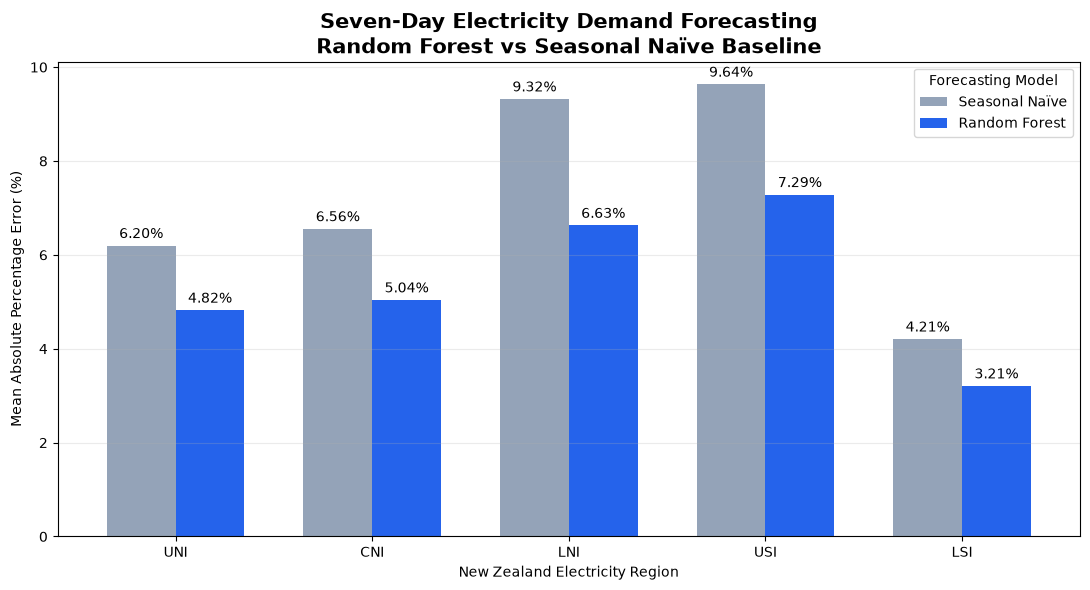

In [7]:
# Prepare chart data
plot_df = baseline_comparison.set_index("Region")[
    ["Baseline_MAPE", "RF_MAPE"]
]

# Create comparison chart
ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.7,
    color=["#94A3B8", "#2563EB"]
)

plt.title(
    "Seven-Day Electricity Demand Forecasting\n"
    "Random Forest vs Seasonal Naïve Baseline",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("New Zealand Electricity Region")
plt.ylabel("Mean Absolute Percentage Error (%)")

plt.xticks(rotation=0)

plt.legend(
    ["Seasonal Naïve", "Random Forest"],
    title="Forecasting Model"
)

plt.grid(axis="y", alpha=0.25)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()

# Save figure
figures_dir = Path.cwd().parent / "figures"
figures_dir.mkdir(exist_ok=True)

plt.savefig(
    figures_dir / "regional_forecasting_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Training, Validation and Test Strategy

To ensure reliable model evaluation, we introduce three
chronological datasets.

- Training: Before 1 April 2026
- Validation: 1 April – 30 June 2026
- Testing: 1 July – 31 October 2026

Training forecast targets must end before the validation period.

Validation forecast targets must end before the test period.

The validation dataset is used to select the optimal lookback
window (7, 14 or 28 days).

The test dataset is reserved for final model evaluation.

In [8]:
train_end = pd.Timestamp("2026-04-01")
test_start = pd.Timestamp("2026-07-01")

regional_splits = {}

for region in regions:

    regional_splits[region] = {}

    for lookback in lookback_windows:

        X, y, dates = create_forecast_sequences(
            regional_profiles[region],
            lookback_days=lookback
        )

        forecast_end = dates + pd.Timedelta(days=7)

        train_mask = forecast_end <= train_end

        val_mask = (
            (dates >= train_end)
            & (forecast_end <= test_start)
        )

        test_mask = dates >= test_start

        regional_splits[region][lookback] = {
            "X_train": X[train_mask],
            "y_train": y[train_mask],
            "X_val": X[val_mask],
            "y_val": y[val_mask],
            "X_test": X[test_mask],
            "y_test": y[test_mask],
            "val_dates": dates[val_mask],
            "test_dates": dates[test_mask]
        }

    print(
        f"{region}: "
        f"{len(regional_splits[region][14]['X_train'])} training, "
        f"{len(regional_splits[region][14]['X_val'])} validation, "
        f"{len(regional_splits[region][14]['X_test'])} testing"
    )

UNI: 402 training, 85 validation, 89 testing
CNI: 402 training, 85 validation, 89 testing
LNI: 402 training, 85 validation, 89 testing
USI: 402 training, 85 validation, 89 testing
LSI: 402 training, 85 validation, 89 testing


## 9. Lookback Window Selection Using Validation Data

We train Random Forest models using three historical lookback
windows: 7, 14 and 28 days.

Each model predicts seven days of electricity demand.

Model selection is based exclusively on validation MAPE.

The test dataset remains unused during model selection.

In [9]:
validation_results = []
validation_models = {}

for region in regions:

    print(f"\nRegion: {region}")
    print("-" * 40)

    validation_models[region] = {}

    for lookback in lookback_windows:

        dataset = regional_splits[region][lookback]

        model = RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            dataset["X_train"],
            dataset["y_train"]
        )

        predictions = model.predict(dataset["X_val"])

        actual = dataset["y_val"]

        mape = np.mean(
            np.abs((actual - predictions) / actual)
        ) * 100

        validation_results.append({
            "Region": region,
            "Lookback": lookback,
            "Validation_MAPE": mape
        })

        validation_models[region][lookback] = model

        print(
            f"{lookback:2d} days | "
            f"Validation MAPE: {mape:.2f}%"
        )

validation_df = pd.DataFrame(validation_results)

# Select best lookback for each region
best_validation = validation_df.loc[
    validation_df.groupby("Region")["Validation_MAPE"].idxmin()
].sort_values("Region")

print("\nBest Lookback Windows — Validation")
display(best_validation.round(2))


Region: UNI
----------------------------------------
 7 days | Validation MAPE: 4.57%
14 days | Validation MAPE: 4.47%
28 days | Validation MAPE: 4.36%

Region: CNI
----------------------------------------
 7 days | Validation MAPE: 4.89%
14 days | Validation MAPE: 4.73%
28 days | Validation MAPE: 4.63%

Region: LNI
----------------------------------------
 7 days | Validation MAPE: 6.73%
14 days | Validation MAPE: 6.73%
28 days | Validation MAPE: 6.89%

Region: USI
----------------------------------------
 7 days | Validation MAPE: 7.49%
14 days | Validation MAPE: 7.42%
28 days | Validation MAPE: 7.24%

Region: LSI
----------------------------------------
 7 days | Validation MAPE: 3.08%
14 days | Validation MAPE: 3.08%
28 days | Validation MAPE: 3.16%

Best Lookback Windows — Validation


,Region,Lookback,Validation_MAPE
5,CNI,28,4.63
7,LNI,14,6.73
13,LSI,14,3.08
2,UNI,28,4.36
11,USI,28,7.24


9.1 Validation Results and Model Selection

Results

The Random Forest models were evaluated using three historical lookback windows (7, 14 and 28 days). Each model predicts seven days of half-hourly electricity demand.

The validation period covers April–June 2026. Model selection was based on the lowest Mean Absolute Percentage Error (MAPE).

Region	Selected Lookback	Validation MAPE
UNI — Upper North Island	28 days	4.36%
CNI — Central North Island	28 days	4.63%
LNI — Lower North Island	14 days	6.73%
USI — Upper South Island	28 days	7.24%
LSI — Lower South Island	14 days	3.08%

Key Findings

1. Longer historical windows improved validation accuracy in some regions.

The 28-day lookback produced the lowest validation error in UNI, CNI and USI. This suggests that demand patterns extending beyond two weeks may provide useful predictive information.

2. The optimal lookback varies by region.

LNI and LSI achieved their lowest validation errors using 14 days of historical demand. This indicates that a single lookback configuration may not be optimal across all five regions.

3. Forecasting accuracy differs geographically.

LSI achieved the lowest validation MAPE (3.08%), while USI recorded the highest (7.24%). These differences suggest varying levels of predictability across regional electricity demand patterns.

4. Additional historical data does not guarantee better predictions.

The 28-day lookback did not produce the best results in every region. Increasing the input window also increases the number of features and computational requirements.

Model Selection Decision

Based on validation performance, the final forecasting models will use:

* 28-day lookback: UNI, CNI and USI.
* 14-day lookback: LNI and LSI.

All models will retain a seven-day forecasting horizon.

Next Stage

The selected models will be retrained using historical data available before 1 July 2026.

Their performance will then be evaluated on the held-out July–October 2026 test period.

This separation ensures that the final evaluation does not directly influence the selection of historical lookback windows.

Limitations

The validation windows overlap, meaning individual demand observations appear in multiple forecasts. Consequently, the validation examples should not be interpreted as statistically independent.

Furthermore, the differences between some lookback configurations are small. Additional validation periods would be required to establish whether the selected configurations consistently outperform alternatives.

## 10. Final Regional Model Training and Evaluation

### Objective

Train the final Random Forest forecasting models using the optimal
historical lookback window selected during validation.

Each model predicts seven days (336 half-hour periods) of
electricity demand.

### Selected Model Configurations

| Region | Historical Lookback | Forecast Horizon |
|---|---|---|
| UNI | 28 days | 7 days |
| CNI | 28 days | 7 days |
| LNI | 14 days | 7 days |
| USI | 28 days | 7 days |
| LSI | 14 days | 7 days |

### Training Strategy

The models are retrained using all eligible historical observations
before 1 July 2026, including the previous validation period.

The final test period covers July–October 2026 and remains
excluded from training.

Training examples are included only when their entire seven-day
target period ends before the test period begins.

### Model Configuration

- Algorithm: Multi-Output Random Forest Regressor
- Number of trees: 100
- Maximum tree depth: 15
- Minimum samples per leaf: 2
- Random state: 42
- Forecast horizon: 336 half-hour periods

### Evaluation

The final models are evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Percentage Error (MAPE)

Each model is also compared against a seasonal naïve baseline,
which repeats the electricity demand pattern from the previous week.

The objective is to determine whether the selected Random Forest
models provide improved forecasting accuracy across all five
New Zealand electricity regions.

In [10]:
# ============================================================
# FINAL REGIONAL RANDOM FOREST MODELS
# ============================================================

import time

final_models = {}
final_results = []

test_start = pd.Timestamp("2026-07-01")

for region in regions:

    # Get optimal lookback selected during validation
    selected = best_validation[
        best_validation["Region"] == region
    ].iloc[0]

    lookback = int(selected["Lookback"])

    # Generate forecasting sequences
    X, y, dates = create_forecast_sequences(
        regional_profiles[region],
        lookback_days=lookback,
        forecast_days=7
    )

    # Chronological split
    # Entire training target must finish before test period
    train_mask = (
        dates + pd.Timedelta(days=7) <= test_start
    )

    test_mask = dates >= test_start

    X_train = X[train_mask]
    y_train = y[train_mask]

    X_test = X[test_mask]
    y_test = y[test_mask]

    # Initialise Random Forest
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    # Train model
    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Generate predictions
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(
        y_test.ravel(),
        predictions.ravel()
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test.ravel(),
            predictions.ravel()
        )
    )

    mape = np.mean(
        np.abs((y_test - predictions) / y_test)
    ) * 100

    # Seasonal naïve baseline
    # Repeat demand from the previous seven days
    baseline_predictions = X_test[:, -336:]

    baseline_mape = np.mean(
        np.abs(
            (y_test - baseline_predictions) / y_test
        )
    ) * 100

    # Calculate percentage improvement
    improvement = (
        (baseline_mape - mape) / baseline_mape
    ) * 100

    # Store trained model
    final_models[region] = model

    # Store evaluation results
    final_results.append({
        "Region": region,
        "Lookback": lookback,
        "Train_Examples": len(X_train),
        "Test_Examples": len(X_test),
        "MAE": mae,
        "RMSE": rmse,
        "Test_MAPE": mape,
        "Baseline_MAPE": baseline_mape,
        "Improvement_%": improvement,
        "Training_Time": training_time
    })

    print(
        f"{region} | "
        f"Lookback: {lookback} days | "
        f"MAPE: {mape:.2f}% | "
        f"Baseline: {baseline_mape:.2f}% | "
        f"Improvement: {improvement:.2f}%"
    )

# Create results DataFrame
final_results_df = pd.DataFrame(final_results)

print("\nFINAL REGIONAL FORECASTING RESULTS")
print("-" * 65)

display(final_results_df.round(2))

UNI | Lookback: 28 days | MAPE: 5.13% | Baseline: 6.20% | Improvement: 17.22%
CNI | Lookback: 28 days | MAPE: 5.17% | Baseline: 6.56% | Improvement: 21.09%
LNI | Lookback: 14 days | MAPE: 6.75% | Baseline: 9.35% | Improvement: 27.79%
USI | Lookback: 28 days | MAPE: 7.43% | Baseline: 9.64% | Improvement: 22.89%
LSI | Lookback: 14 days | MAPE: 3.16% | Baseline: 4.18% | Improvement: 24.35%

FINAL REGIONAL FORECASTING RESULTS
-----------------------------------------------------------------


,Region,Lookback,Train_Examples,Test_Examples,MAE,RMSE,Test_MAPE,Baseline_MAPE,Improvement_%,Training_Time
0,UNI,28,465,82,0.04,0.05,5.13,6.20,17.22,12.52
1,CNI,28,465,82,0.03,0.04,5.17,6.56,21.09,12.15
2,LNI,14,493,89,0.03,0.03,6.75,9.35,27.79,6.95
3,USI,28,465,82,0.03,0.04,7.43,9.64,22.89,12.19
4,LSI,14,493,89,0.02,0.02,3.16,4.18,24.35,5.93


## 10.1 Final Model Evaluation — Results and Discussion

### Overview

Five multi-output Random Forest models were trained to forecast
seven days of electricity demand across New Zealand's five
electricity regions.

Historical lookback windows were selected using validation data,
and the selected configurations were retrained using observations
available before 1 July 2026.

Final evaluation was conducted on the held-out July–October
2026 test period.

### Final Test Results

| Region | Lookback | RF MAPE | Baseline MAPE | Error Reduction |
|---|---|---|---|---|
| UNI | 28 days | 5.13% | 6.20% | 17.22% |
| CNI | 28 days | 5.17% | 6.56% | 21.09% |
| LNI | 14 days | 6.75% | 9.35% | 27.79% |
| USI | 28 days | 7.43% | 9.64% | 22.89% |
| LSI | 14 days | 3.16% | 4.18% | 24.35% |

### Key Findings

**1. Consistent improvement over the baseline**

Random Forest outperformed the seasonal naïve forecasting
method in all five regions.

Relative reductions in MAPE ranged from 17.22% to 27.79%.

**2. Regional differences in forecasting accuracy**

LSI achieved the lowest test MAPE (3.16%), while USI recorded
the highest (7.43%).

These results indicate that forecasting accuracy varies
between regions.

**3. Benefits of region-specific model configurations**

Validation-based model selection identified different
historical lookback windows across the five regions.

UNI, CNI and USI used 28-day lookback windows, while
LNI and LSI used 14-day windows.

**4. Generalisation to unseen data**

The final models were evaluated on a held-out test period
that was not used to select lookback configurations.

All five models maintained an advantage over the
seasonal naïve baseline.

### Limitations

The models use historical electricity demand without
additional explanatory variables such as temperature,
public holidays or economic activity.

Forecast windows overlap, meaning individual observations
can contribute to multiple evaluation forecasts.

The results represent performance over one held-out
test period rather than multiple independent forecasting
periods.

### Conclusion

Multi-output Random Forest provides an effective approach
for seven-day regional electricity demand forecasting.

Across all five New Zealand electricity regions, the
models achieved lower forecasting errors than the
seasonal naïve baseline.

The findings support further investigation into weather
features, calendar effects and alternative forecasting
architectures.

## 11. Saving the Final Regional Forecasting Models

### Objective

Save the five trained Random Forest models for future forecasting
without requiring retraining.

Each model uses a region-specific historical lookback window
and produces seven days (336 half-hour periods) of predictions.

### Saved Models

| Region | Lookback | Forecast Horizon |
|---|---|---|
| UNI | 28 days | 7 days |
| CNI | 28 days | 7 days |
| LNI | 14 days | 7 days |
| USI | 28 days | 7 days |
| LSI | 14 days | 7 days |

### Storage

The trained models will be saved in the project's `models/`
directory using Python's joblib library.

A separate configuration file will store each region's
selected lookback window and forecasting horizon.

This allows the models to be loaded and reused in future
Python scripts or forecasting applications.

In [11]:
import joblib
from pathlib import Path

# Create models directory
models_dir = Path.cwd().parent / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Store model configurations
model_configurations = {}

for region in regions:

    # Retrieve selected lookback
    selected = best_validation[
        best_validation["Region"] == region
    ].iloc[0]

    lookback = int(selected["Lookback"])

    # Get trained model
    model = final_models[region]

    # Save model
    model_path = models_dir / f"random_forest_{region}_7day.pkl"

    joblib.dump(model, model_path)

    # Save configuration
    model_configurations[region] = {
        "lookback_days": lookback,
        "forecast_days": 7,
        "periods_per_day": 48,
        "input_features": lookback * 48,
        "output_predictions": 336
    }

    print(f"Saved: {model_path.name}")

# Save all configurations
config_path = models_dir / "regional_model_config.pkl"

joblib.dump(model_configurations, config_path)

print("\nAll five regional models saved successfully.")
print(f"Location: {models_dir}")

Saved: random_forest_UNI_7day.pkl
Saved: random_forest_CNI_7day.pkl
Saved: random_forest_LNI_7day.pkl
Saved: random_forest_USI_7day.pkl
Saved: random_forest_LSI_7day.pkl

All five regional models saved successfully.
Location: /Users/javiermorande/Desktop/nz-electricity-forecasting/models


## 11.1 Model Loading and Verification

### Objective

Verify that the saved Random Forest models can be loaded
successfully and used to generate electricity demand forecasts.

For each region, we will:

- Load the trained model from disk.
- Load its saved configuration.
- Retrieve the required historical demand observations.
- Generate a seven-day forecast.
- Verify that the model produces 336 predictions.

This confirms that the models are ready for reuse in future
forecasting applications.

In [12]:
import joblib
import numpy as np
from pathlib import Path

models_dir = Path.cwd().parent / "models"

# Load saved configurations
configurations = joblib.load(
    models_dir / "regional_model_config.pkl"
)

for region in regions:

    # Load saved model
    model = joblib.load(
        models_dir / f"random_forest_{region}_7day.pkl"
    )

    # Retrieve configuration
    config = configurations[region]

    lookback = config["lookback_days"]

    # Retrieve the latest complete historical days
    profiles = regional_profiles[region]

    historical = profiles.iloc[-lookback:]

    # Flatten into one input row
    X_new = historical.to_numpy().flatten().reshape(1, -1)

    # Generate seven-day forecast
    predictions = model.predict(X_new)

    print(
        f"{region} | "
        f"Lookback: {lookback} days | "
        f"Input features: {X_new.shape[1]} | "
        f"Predictions: {predictions.shape[1]} | "
        f"Status: {'PASS' if predictions.shape == (1, 336) else 'FAIL'}"
    )

UNI | Lookback: 28 days | Input features: 1344 | Predictions: 336 | Status: PASS
CNI | Lookback: 28 days | Input features: 1344 | Predictions: 336 | Status: PASS
LNI | Lookback: 14 days | Input features: 672 | Predictions: 336 | Status: PASS
USI | Lookback: 28 days | Input features: 1344 | Predictions: 336 | Status: PASS
LSI | Lookback: 14 days | Input features: 672 | Predictions: 336 | Status: PASS


## 12. National Aggregate Forecast Evaluation

### Objective

Evaluate the accuracy of national electricity demand forecasts
by combining predictions from the five regional Random Forest models.

### Methodology

Each regional model generates seven-day electricity demand
forecasts using its selected historical lookback window.

National electricity demand is calculated by summing the
predictions from all five regions at matching timestamps.

### Evaluation Strategy

To ensure a fair comparison:

1. Use the existing held-out test period.
2. Align regional forecasts using common forecast start dates.
3. Sum regional predictions to obtain national demand.
4. Compare predictions against observed national demand.
5. Calculate MAE, RMSE and MAPE.

### Research Question

Does aggregating five independently trained regional models
produce accurate national electricity demand forecasts?

### Important Consideration

Regional forecasting errors may partially offset one another
when predictions are aggregated.

Consequently, national forecasting accuracy may differ from
the individual regional forecasting errors.

In [13]:
# ============================================================
# ALIGN REGIONAL TEST FORECAST WINDOWS
# ============================================================

common_test_dates = None

for region in regions:

    # Retrieve selected lookback
    selected = best_validation[
        best_validation["Region"] == region
    ].iloc[0]

    lookback = int(selected["Lookback"])

    # Retrieve test dates
    dates = regional_splits[region][lookback]["test_dates"]

    if common_test_dates is None:
        common_test_dates = dates
    else:
        common_test_dates = common_test_dates.intersection(dates)

    print(
        f"{region} | "
        f"Lookback: {lookback} days | "
        f"Available test windows: {len(dates)}"
    )

common_test_dates = common_test_dates.sort_values()

print("\nCOMMON NATIONAL FORECAST WINDOWS")
print("-" * 45)
print(f"Total aligned windows: {len(common_test_dates)}")

if len(common_test_dates) > 0:
    print(f"First forecast: {common_test_dates.min().date()}")
    print(f"Last forecast: {common_test_dates.max().date()}")
else:
    print("No common forecast windows found.")

UNI | Lookback: 28 days | Available test windows: 82
CNI | Lookback: 28 days | Available test windows: 82
LNI | Lookback: 14 days | Available test windows: 89
USI | Lookback: 28 days | Available test windows: 82
LSI | Lookback: 14 days | Available test windows: 89

COMMON NATIONAL FORECAST WINDOWS
---------------------------------------------
Total aligned windows: 82
First forecast: 2026-07-01
Last forecast: 2026-09-20


## 12.1 National Forecast Aggregation

### Objective

Combine the five regional Random Forest forecasts to estimate
national electricity demand and evaluate prediction accuracy.

### Methodology

The evaluation uses 82 common seven-day forecast windows
from the held-out test period.

For each forecast window:

1. Generate predictions for all five regions.
2. Sum regional predictions at matching half-hourly periods.
3. Sum observed regional demand to obtain actual national demand.
4. Compare predicted and actual national demand.

### Evaluation Metrics

- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- MAPE: Mean Absolute Percentage Error

All five regional models use the lookback configurations
selected during validation.

In [14]:
# ============================================================
# NATIONAL AGGREGATE FORECAST EVALUATION
# ============================================================

national_predictions = []
national_actuals = []
national_baselines = []

for forecast_date in common_test_dates:

    regional_predictions = []
    regional_actuals = []
    regional_baselines = []

    for region in regions:

        # Retrieve selected lookback
        selected = best_validation[
            best_validation["Region"] == region
        ].iloc[0]

        lookback = int(selected["Lookback"])

        # Retrieve test dataset
        dataset = regional_splits[region][lookback]

        # Find matching forecast date
        idx = dataset["test_dates"].get_loc(forecast_date)

        X = dataset["X_test"][idx:idx + 1]
        y = dataset["y_test"][idx]

        # Generate regional forecast
        prediction = final_models[region].predict(X)[0]

        # Seasonal naive baseline
        baseline = X[0, -336:]

        regional_predictions.append(prediction)
        regional_actuals.append(y)
        regional_baselines.append(baseline)

    # Sum all five regions
    national_predictions.append(
        np.sum(regional_predictions, axis=0)
    )

    national_actuals.append(
        np.sum(regional_actuals, axis=0)
    )

    national_baselines.append(
        np.sum(regional_baselines, axis=0)
    )

# Convert to NumPy arrays
national_predictions = np.array(national_predictions)
national_actuals = np.array(national_actuals)
national_baselines = np.array(national_baselines)

# Calculate national forecasting metrics
national_mae = mean_absolute_error(
    national_actuals.ravel(),
    national_predictions.ravel()
)

national_rmse = np.sqrt(
    mean_squared_error(
        national_actuals.ravel(),
        national_predictions.ravel()
    )
)

national_mape = np.mean(
    np.abs(
        (national_actuals - national_predictions)
        / national_actuals
    )
) * 100

# Calculate baseline MAPE
national_baseline_mape = np.mean(
    np.abs(
        (national_actuals - national_baselines)
        / national_actuals
    )
) * 100

# Calculate relative improvement
national_improvement = (
    (national_baseline_mape - national_mape)
    / national_baseline_mape
) * 100

print("NATIONAL FORECAST EVALUATION")
print("-" * 45)

print(f"Forecast windows: {len(common_test_dates)}")
print(f"Forecast horizon: 7 days")
print(f"National MAE: {national_mae:.4f} GWh")
print(f"National RMSE: {national_rmse:.4f} GWh")
print(f"National MAPE: {national_mape:.2f}%")
print(f"Baseline MAPE: {national_baseline_mape:.2f}%")
print(f"Relative improvement: {national_improvement:.2f}%")

NATIONAL FORECAST EVALUATION
---------------------------------------------
Forecast windows: 82
Forecast horizon: 7 days
National MAE: 0.1119 GWh
National RMSE: 0.1480 GWh
National MAPE: 4.19%
Baseline MAPE: 5.50%
Relative improvement: 23.86%


12.2 National Forecasting Results and Discussion

Overview

The five independently trained regional Random Forest models were combined to evaluate national electricity demand forecasting accuracy.

The evaluation used 82 aligned seven-day forecast windows from the held-out test period, with forecast start dates ranging from 1 July to 20 September 2026.

Regional predictions were summed at matching half-hourly periods to obtain national electricity demand forecasts.

Evaluation Results

Metric	Result
Forecast horizon	7 days
Forecast windows	82
Mean Absolute Error (MAE)	0.1119 GWh
Root Mean Squared Error (RMSE)	0.1480 GWh
Random Forest MAPE	4.19%
Seasonal Naïve MAPE	5.50%
Relative MAPE Reduction	23.86%

Key Findings

1. National forecasting accuracy

The combined regional models achieved a national MAPE of 4.19%.

This indicates that the average absolute percentage error across the evaluated national demand predictions was approximately 4.19%.

2. Improvement over the seasonal naïve baseline

The Random Forest models outperformed the seasonal naïve forecasting method, which achieved a MAPE of 5.50%.

The combined models reduced MAPE by 23.86% relative to the baseline.

3. Benefits of regional aggregation

National forecasts were generated by summing predictions from five independently trained regional models.

Forecasting errors may partially offset one another during aggregation, potentially improving national percentage accuracy compared with individual regional forecasts.

4. Multi-output forecasting performance

The models generated 336 half-hourly predictions for each seven-day forecast window.

This demonstrates the feasibility of using multi-output Random Forest regression for medium-term electricity demand forecasting.

Limitations

* The evaluation used overlapping seven-day forecast windows, meaning individual observations contributed to multiple forecast evaluations.
* Regional models were trained independently, without explicitly modelling relationships between regions.
* The models did not incorporate weather forecasts, public holidays or other external explanatory variables.
* The test period was inspected during earlier exploratory experiments, so it should not be considered completely untouched throughout the project.
* Forecasting performance may differ across seasons and future periods.

Conclusion

The combined regional Random Forest models achieved a national electricity demand forecasting MAPE of 4.19%, outperforming the seasonal naïve baseline by 23.86% in relative MAPE reduction.

These findings demonstrate that region-specific multi-output Random Forest models can provide useful seven-day electricity demand forecasts for New Zealand.

Further research could investigate weather-based predictors, alternative machine-learning architectures and evaluation across additional forecasting periods.

## 12.3 Actual vs Predicted National Electricity Demand

### Objective

Visualise the forecasting accuracy of the combined regional
Random Forest models.

### Methodology

A seven-day forecast window is selected from the held-out
test dataset.

National electricity demand is calculated by aggregating
the predictions and actual observations across all five regions.

### Visualisation

The chart compares:

- Actual national electricity demand.
- Predicted national electricity demand.
- Seven consecutive days of half-hourly observations.

### Purpose

This visualisation helps assess how closely the model
captures daily electricity demand patterns, including
peak demand and overnight reductions.

The comparison complements the national forecasting
MAPE of 4.19% calculated across all test windows.

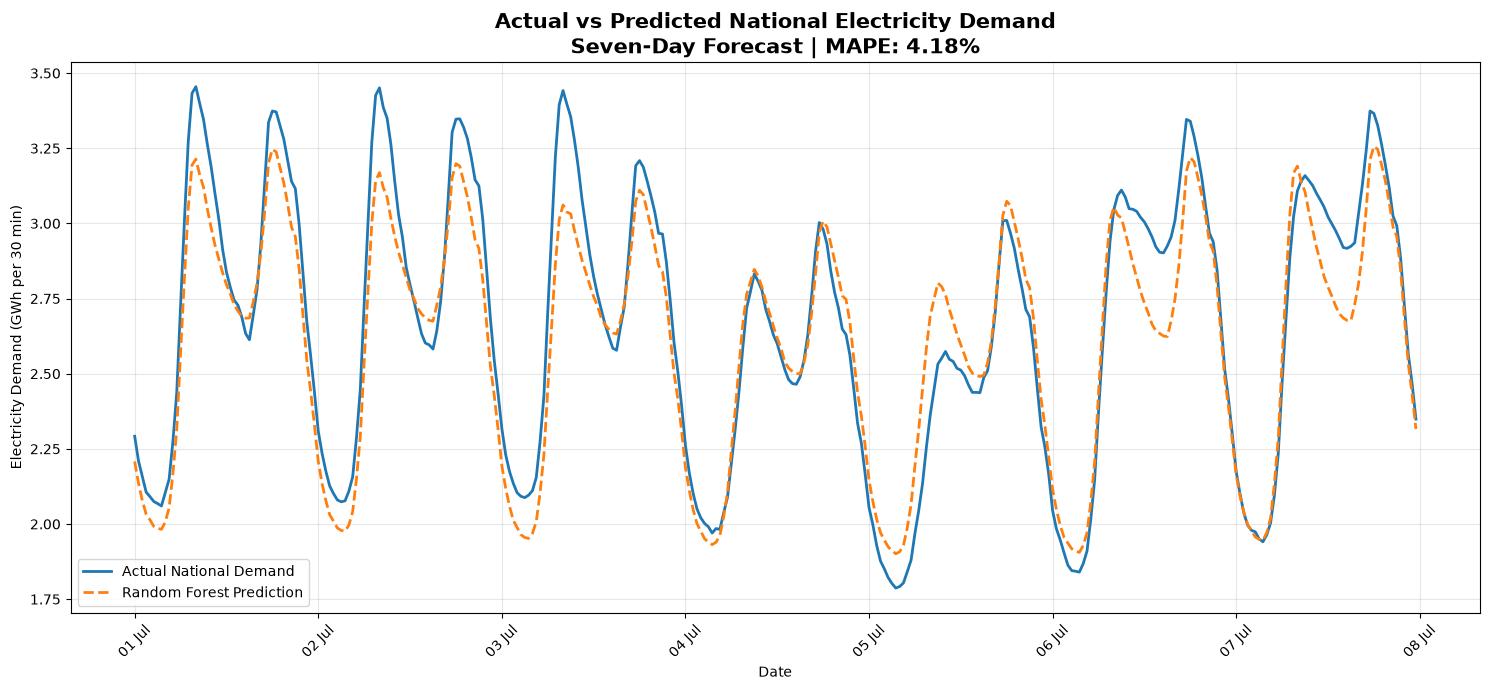

Forecast start: 2026-07-01
Seven-day forecast MAPE: 4.18%
Chart saved successfully.


In [15]:
# ============================================================
# ACTUAL VS PREDICTED NATIONAL ELECTRICITY DEMAND
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Select first common seven-day test forecast
forecast_date = common_test_dates[0]

# Retrieve actual and predicted demand
actual = national_actuals[0]
predicted = national_predictions[0]

# Create half-hourly timestamps
timestamps = pd.date_range(
    start=forecast_date,
    periods=336,
    freq="30min"
)

# Calculate MAPE for this forecast window
window_mape = np.mean(
    np.abs((actual - predicted) / actual)
) * 100

# Create figure
fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(
    timestamps,
    actual,
    label="Actual National Demand",
    linewidth=2
)

ax.plot(
    timestamps,
    predicted,
    label="Random Forest Prediction",
    linewidth=2,
    linestyle="--"
)

# Formatting
ax.set_title(
    "Actual vs Predicted National Electricity Demand\n"
    f"Seven-Day Forecast | MAPE: {window_mape:.2f}%",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Electricity Demand (GWh per 30 min)")

ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

ax.legend()
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

# Save figure
figures_dir = Path.cwd().parent / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "national_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Forecast start: {forecast_date.date()}")
print(f"Seven-day forecast MAPE: {window_mape:.2f}%")
print("Chart saved successfully.")

## 13. Final Conclusion — Regional and National Electricity Demand Forecasting

### Project Summary

This project developed a machine-learning forecasting pipeline to predict
New Zealand electricity demand using historical half-hourly observations.

Five independent Random Forest models were trained to forecast electricity
demand across the following regions:

- Upper North Island (UNI)
- Central North Island (CNI)
- Lower North Island (LNI)
- Upper South Island (USI)
- Lower South Island (LSI)

Each model generates 336 half-hourly predictions, representing a
seven-day forecasting horizon.

Historical lookback windows of 7, 14 and 28 days were evaluated,
with the best configuration for each region selected using
validation performance.

### Key Results

| Evaluation Metric | Result |
|---|---:|
| Forecast horizon | 7 days |
| Regional models | 5 |
| Common national test windows | 82 |
| National MAE | 0.1119 GWh |
| National RMSE | 0.1480 GWh |
| National MAPE | 4.19% |
| Seasonal Naïve MAPE | 5.50% |
| Relative MAPE Reduction | 23.86% |
| Example Seven-Day Forecast MAPE | 4.18% |

### Main Findings

**1. Machine learning improved forecasting accuracy.**

The combined Random Forest models achieved a national MAPE of 4.19%,
outperforming the seasonal naïve baseline of 5.50%.

This represents a 23.86% relative reduction in forecasting error.

**2. Regional modelling was effective.**

Training separate models allowed each region to use its own
historical demand patterns and selected lookback window.

**3. National aggregation produced accurate forecasts.**

Combining the five regional predictions generated national
electricity demand forecasts that closely followed observed
daily consumption patterns.

Regional forecasting errors may partially offset one another,
although this effect was not independently quantified.

**4. The models captured daily electricity demand cycles.**

Visual inspection demonstrated that the combined forecasts
generally reproduced daily demand peaks and overnight reductions.

However, some peak demand periods were underestimated.

### Limitations

Several limitations should be considered:

- The models rely primarily on historical electricity demand.
- Weather forecasts and public holidays were not included.
- The evaluation contains overlapping seven-day forecast windows.
- Earlier exploratory experiments inspected the test period.
- Model accuracy may change across different seasons.
- Random Forest models may struggle with unusual demand patterns.

Consequently, the reported results should not be interpreted
as guaranteed forecasting performance on future unseen data.

### Future Improvements

Potential extensions include:

1. Incorporating temperature and weather forecasts.
2. Adding public holiday and calendar indicators.
3. Comparing Random Forest with XGBoost and neural networks.
4. Evaluating performance using non-overlapping forecast windows.
5. Developing an automated forecasting pipeline.
6. Creating an interactive electricity demand dashboard.

### Final Conclusion

This project demonstrates that multi-output Random Forest regression
can provide useful seven-day electricity demand forecasts for
New Zealand.

The five regional models achieved a combined national MAPE of
4.19%, reducing forecasting error by 23.86% relative to the
seasonal naïve baseline.

The completed forecasting pipeline supports regional predictions,
national aggregation, model evaluation, visualisation and future
forecast generation.

These results provide a foundation for further research into
machine-learning-based electricity demand forecasting.

---

**Project Status:** Forecasting pipeline and evaluation completed.

**Next Phase:** GitHub documentation, reproducibility improvements
and portfolio presentation.